In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 500)
pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [3]:
df = pd.read_csv("datasets/red-wine-quality/winequality-red.csv")

In [4]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5
1,7.800,0.880,0.000,2.600,0.098,25.000,67.000,0.997,3.200,0.680,9.800,5
2,7.800,0.760,0.040,2.300,0.092,15.000,54.000,0.997,3.260,0.650,9.800,5
3,11.200,0.280,0.560,1.900,0.075,17.000,60.000,0.998,3.160,0.580,9.800,6
4,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5


In [5]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality'], dtype='object')

In [6]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_score, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming X and y are already defined
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

rf_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 8, 10],
    'min_samples_split': [2, 5, 8],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'class_weight': ['balanced'],
    'max_leaf_nodes': [50, 100, None],
    'min_impurity_decrease': [0.0, 0.01]
}

rf = RandomForestClassifier(
    random_state=42,
    bootstrap=True,
    oob_score=True,
    ccp_alpha=0.001,
    criterion='gini'
)

rf_grid = GridSearchCV(
    rf, 
    rf_params, 
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("\nEn iyi Random Forest parametreleri:", rf_grid.best_params_)
print("Random Forest Test Skoru:", rf_grid.score(X_test, y_test))
print("OOB Skor:", rf_grid.best_estimator_.oob_score_)

feature_importance = pd.DataFrame({
    'feature': [f'Feature{i+1}' for i in range(X.shape[1])],
    'importance': rf_grid.best_estimator_.feature_importances_
}).sort_values('importance', ascending=False)

print("\nÖzellik Önem Sıralaması:")
print(feature_importance)

def plot_learning_curve(estimator, X, y, title="Learning Curve"):
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, 
        X, 
        y, 
        cv=5,
        n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10),
        scoring='accuracy'
    )
    
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)
    
    plt.figure(figsize=(10, 6))
    plt.plot(train_sizes, train_mean, label='Eğitim skoru', color='blue', marker='o')
    plt.plot(train_sizes, test_mean, label='Cross-validation skoru', color='red', marker='s')
    
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
    plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color='red')
    
    plt.title(title)
    plt.xlabel('Eğitim Örnekleri Sayısı')
    plt.ylabel('Skor')
    plt.legend(loc='best')
    plt.grid(True)
    
    gap = train_mean[-1] - test_mean[-1]
    print(f"\nModel Analizi:")
    print(f"Son eğitim skoru: {train_mean[-1]:.3f}")
    print(f"Son validasyon skoru: {test_mean[-1]:.3f}")
    print(f"Eğitim-Validasyon farkı: {gap:.3f}")
    
    if gap > 0.1:
        print("Uyarı: Model overfitting eğilimi gösteriyor.")
    elif test_mean[-1] < 0.6:
        print("Uyarı: Model underfitting eğilimi gösteriyor.")
    
    plt.show()

plot_learning_curve(rf_grid.best_estimator_, X_scaled, y, "Random Forest Learning Curve")

y_pred = rf_grid.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('Gerçek Değerler')
plt.xlabel('Tahmin Edilen Değerler')
plt.show()

print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(12, 6))
sns.barplot(x='importance', y='feature', data=feature_importance)
plt.title('Özellik Önem Sıralaması')
plt.xlabel('Önem Skoru')
plt.ylabel('Özellikler')
plt.tight_layout()
plt.show()

cv_scores = cross_val_score(rf_grid.best_estimator_, X_scaled, y, cv=5)
print("\nCross Validation Skorları:")
print(f"Ortalama CV Skoru: {cv_scores.mean():.3f} (+/- {cv_scores.std() * 2:.3f})")

print("\nFinal Model Performans Özeti:")
print(f"En İyi Parametreler: {rf_grid.best_params_}")
print(f"Test Seti Doğruluk Oranı: {rf_grid.score(X_test, y_test):.3f}")
print(f"OOB Skor: {rf_grid.best_estimator_.oob_score_:.3f}")
print(f"Cross Validation Ortalama Skoru: {cv_scores.mean():.3f}")

X_df = pd.DataFrame(X_scaled, columns=[f'Feature{i+1}' for i in range(X.shape[1])])
X_df['quality'] = y
top_features = feature_importance.head(3)['feature'].tolist()

plt.figure(figsize=(15, 5))
for i, feature in enumerate(top_features, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(x='quality', y=feature, data=X_df)
    plt.title(f'{feature} vs Quality')
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
for i, feature in enumerate(top_features, 1):
    plt.subplot(1, 3, i)
    sns.scatterplot(x='quality', y=feature, data=X_df)
    plt.title(f'{feature} vs Quality')
plt.tight_layout()
plt.show()

NameError: name 'X' is not defined

## Case Nedir?

- "Vinho Verde" şarabının kırmızı varyantı ile ilgili multiclass classification problemi

- Gizlilik ve lojistik sorunlar nedeniyle, yalnızca fizikokimyasal (girdiler) ve duyusal (çıktı) değişkenler mevcuttur (örneğin, üzüm türleri, şarap markası, şarap satış fiyatı gibi veriler yoktur).

- fixed acidity -> sabit asitlik 
- volatile acidity -> uçucu asitlik
- citric acid -> sitrik asit
- residual sugar -> kalıntı şeker
- chlorides -> klorürler
- free sulfur dioxide -> serbest kükürt dioksit
- total sulfur dioxide -> toplam kükürt dioksit
- density -> yoğunluk
- pH -> pH
- sulphates -> sülfatlar
- alcohol -> alkol
- quality -> kalite

## Preprocessing Functions

In [8]:
def cat_summary(dataframe, col_name, plot=False):
    print(pd.DataFrame({col_name: dataframe[col_name].value_counts(),
                       "Ratio": 100 * dataframe[col_name].value_counts() / len(dataframe)}))
    print("##########################################")
    if plot:
        sns.countplot(x=dataframe[col_name], data=dataframe)
        plt.show()

In [9]:
def check_df(dataframe, head=5):
    print("##################### Shape #####################")
    print(dataframe.shape)
    print("##################### Types #####################")
    print(dataframe.dtypes)
    print("##################### Head #####################")
    print(dataframe.head(head))
    print("##################### Tail #####################")
    print(dataframe.tail(head))
    print("##################### NA #####################")
    print(dataframe.isnull().sum())
    print("##################### Quantiles #####################")
    numeric_columns = dataframe.select_dtypes(include=[np.number]).columns
    print(dataframe[numeric_columns].quantile([0, 0.05, 0.50, 0.95, 0.99, 1]).T)


In [10]:
def num_summary(dataframe, numerical_col, plot=False):
    quantiles = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
    print(dataframe[numerical_col].describe(quantiles).T)

    if plot:
        dataframe[numerical_col].hist(bins=20)
        plt.xlabel(numerical_col)
        plt.title(numerical_col)
        plt.show(block=True)

In [8]:
def outlier_thresholds(dataframe, col_name, q1=0.25, q3=0.75):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range
    return low_limit, up_limit


In [9]:
def check_outlier(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    # Aykırı değerleri boolean mask ile belirle
    outlier_mask = (dataframe[col_name] > up_limit) | (dataframe[col_name] < low_limit)
    # Herhangi bir True değeri var mı diye kontrol et
    return outlier_mask.any()

In [10]:
def replace_with_thresholds(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    dataframe.loc[(dataframe[col_name] < low_limit), col_name] = low_limit
    dataframe.loc[(dataframe[col_name] > up_limit), col_name] = up_limit


In [11]:
def correlation_matrix(dataframe, cols, figsize=(12,10), font_size=10, annot_size=8):
    """
    Veri çerçevesi için gelişmiş korelasyon matrisi görselleştirmesi.
    
    Parameters:
    -----------
    dataframe : pandas DataFrame
        Analiz edilecek veri çerçevesi
    cols : list
        Korelasyon matrisi için kullanılacak kolonlar
    figsize : tuple, default=(12,10)
        Görselleştirme boyutu
    font_size : int, default=10
        Eksen etiketlerinin yazı boyutu
    annot_size : int, default=8
        Korelasyon değerlerinin yazı boyutu
    """
    
    # Figure boyutunu ayarla
    plt.figure(figsize=figsize)
    
    # Korelasyon matrisini hesapla
    corr_matrix = dataframe[cols].corr()
    
    # Maske oluştur (opsiyonel - üst üçgeni gizlemek için)
    # mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    # Isı haritası oluştur
    sns.heatmap(corr_matrix,
                annot=True,                 # Değerleri göster
                fmt='.2f',                  # Değerleri 2 ondalık basamakla göster
                cmap='RdBu_r',             # Renk paleti
                center=0,                   # Renk merkezini 0'a ayarla
                square=True,                # Kare hücreler
                linewidths=0.5,             # Hücre çizgi kalınlığı
                annot_kws={'size': annot_size},  # Korelasyon değerlerinin yazı boyutu
                cbar_kws={'shrink': .8},    # Renk çubuğu boyutu
                linecolor='white')          # Hücre çizgi rengi
    
    # Grafik özelliklerini ayarla
    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)
    plt.title('Değişkenler Arası Korelasyon Matrisi', pad=20, fontsize=font_size+2)
    
    # Layout'u düzenle
    plt.tight_layout()
    
    # Göster
    plt.show(block=True)

In [12]:
def grab_col_names(dataframe, cat_th=10, car_th=20):
    cat_cols = [col for col in dataframe.columns if dataframe[col].dtypes == "O"]
    #numeric olup kategorik olan değişkenler
    num_but_cat = [col for col in dataframe.columns if dataframe[col].nunique() < cat_th and dataframe[col].dtypes != "O"]
    #kategorik olup kardinalitesi yüksek olan değişkenler
    cat_but_car = [col for col in dataframe.columns if dataframe[col].dtypes == "O" and dataframe[col].nunique() > car_th]
    cat_cols += num_but_cat
    cat_cols = [col for col in cat_cols if col not in cat_but_car]
    num_cols = [col for col in dataframe.columns if dataframe[col].dtypes != "O" and col not in num_but_cat]

    print(f"Observations: {dataframe.shape[0]}")
    print(f"Variables: {dataframe.shape[1]}")
    print(f"cat_cols: {len(cat_cols)}")
    print(f"num_cols: {len(num_cols)}")
    print(f"cat_but_car: {len(cat_but_car)}")
    print(f"num_but_cat: {len(num_but_cat)}")
    
    return cat_cols, num_cols, cat_but_car


In [13]:
check_df(df)


NameError: name 'check_df' is not defined

In [14]:
cat_cols, num_cols, cat_but_car = grab_col_names(df)




Observations: 1599
Variables: 12
cat_cols: 1
num_cols: 11
cat_but_car: 0
num_but_cat: 1


In [15]:
cat_cols

['quality']

In [16]:
df.quality.value_counts()

quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64

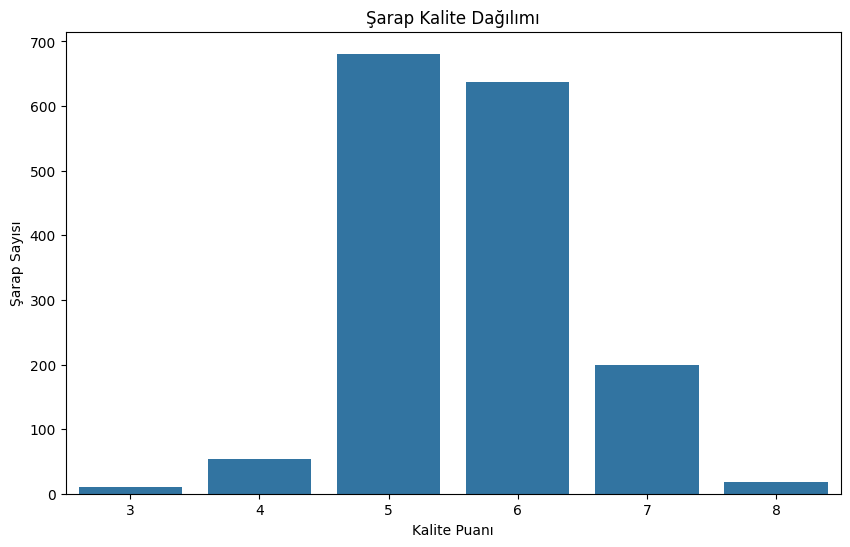

In [17]:
# Kalite Dağılımı
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='quality')
plt.title('Şarap Kalite Dağılımı')
plt.xlabel('Kalite Puanı')
plt.ylabel('Şarap Sayısı')
plt.show()

# Şarapların büyük çoğunluğunun orta kalitede(5-6) olduğunu görüyoruz.
# Düşük kaliteli (3-4) ve yüksek kaliteli (7-8) şarap sayısı azdır.

# Yani üretilen şarapların büyük çoğunluğu orta kalitededir.

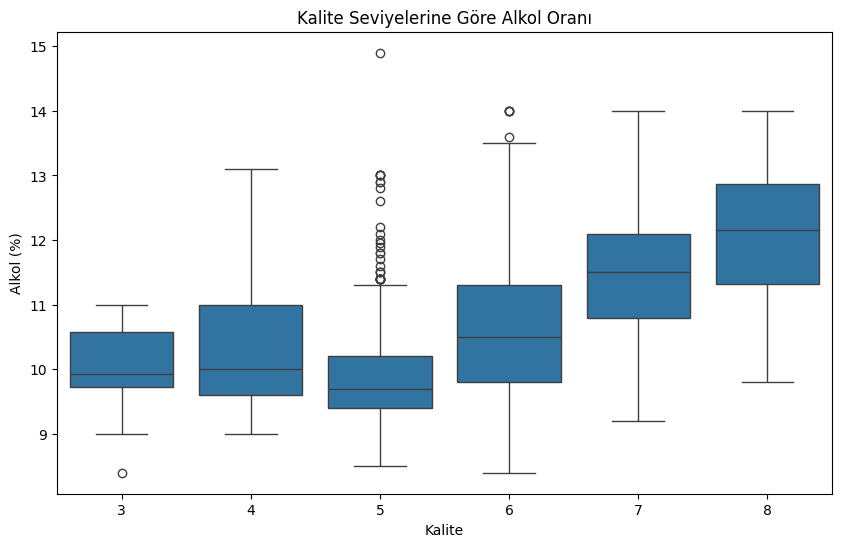

In [18]:
# Kalite ve Alkol İlişkisi
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='quality', y='alcohol')
plt.title('Kalite Seviyelerine Göre Alkol Oranı')
plt.xlabel('Kalite')
plt.ylabel('Alkol (%)')
plt.show()


## Korelasyon Matrisinde de görüldüğü gibi alcohol ve sulphates arasında pozitif bir ilişki
## olduğunu gözlemliyoruz.


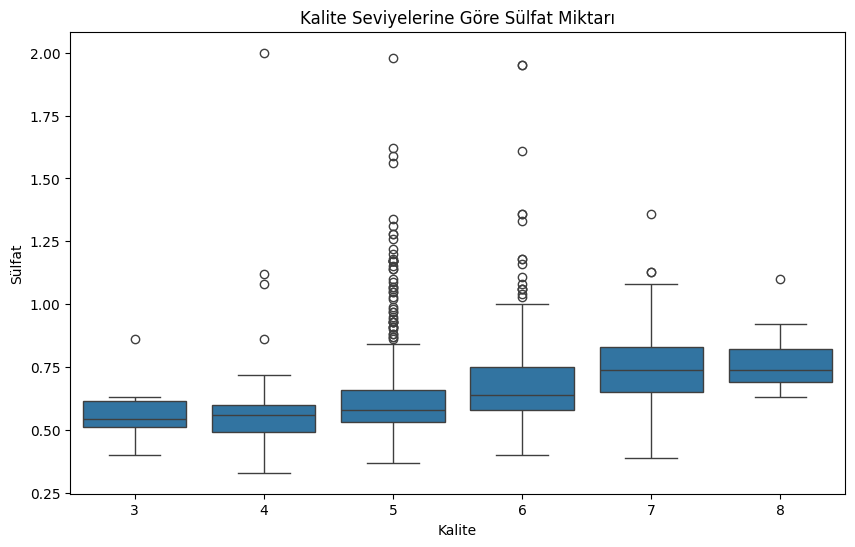

In [19]:
# Kalite ve Sülfat İlişkisi
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='quality', y='sulphates')
plt.title('Kalite Seviyelerine Göre Sülfat Miktarı')
plt.xlabel('Kalite')
plt.ylabel('Sülfat')
plt.show()

## Korelasyon matrisinde de görüldüğü gibi sulphates ile quality arasında pozitif bir 
## ilişki olduğunu gözlemliyoruz.

## Ayrıca oldukça fazla outlier gözlemliyoruz.


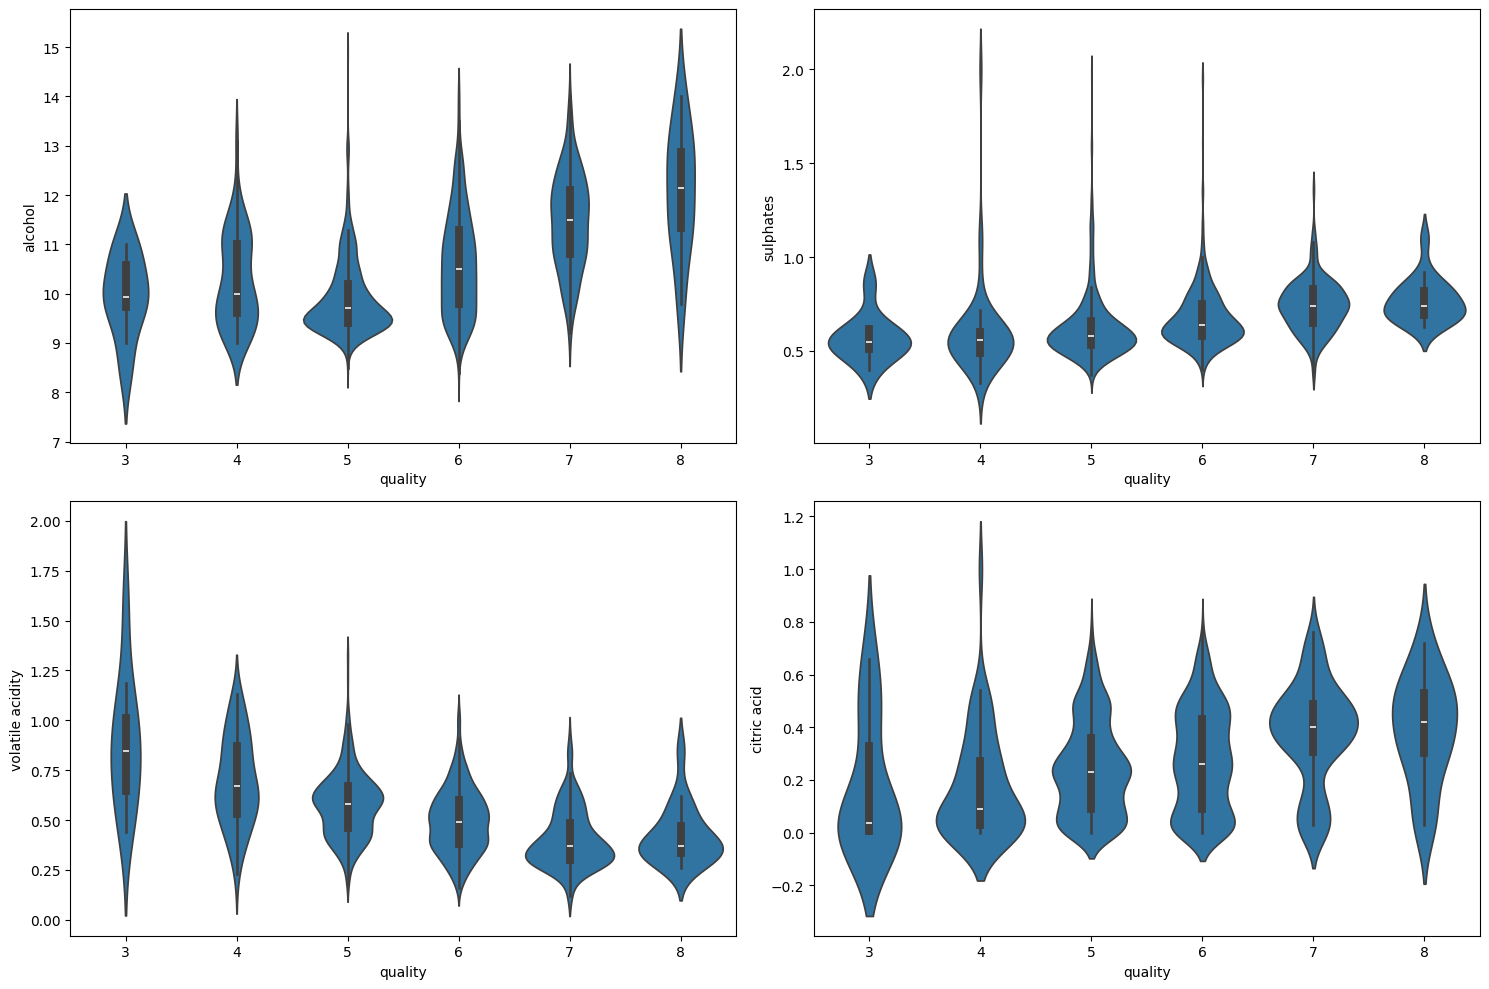

In [20]:
# En Önemli Değişkenlerin Dağılımı
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.violinplot(data=df, x='quality', y='alcohol', ax=axes[0,0])
sns.violinplot(data=df, x='quality', y='sulphates', ax=axes[0,1])
sns.violinplot(data=df, x='quality', y='volatile acidity', ax=axes[1,0])
sns.violinplot(data=df, x='quality', y='citric acid', ax=axes[1,1])
plt.tight_layout()
plt.show()

# 1- Kalite arttıkça alkol oranı da artıyor
# Yüksek kaliteli şaraplarda alkol oranı belirgin şekilde daha yüksek

# 2- Kalite ile sülfat arasında pozitif bir ilişki var fakat çok belirgin değil

# 3- Kalite arttıkça uçucu asitlik azalıyor
# Düşük kaliteli şaraplarda uçucu asitlik daha yüksek


# 4- Kalite arttıkça sitrik asit miktarı da artıyor
## fakat ilişki çok belirgin değil


## Feature Extraction

In [21]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality'], dtype='object')

## Sülfür bazlı özellikler

In [22]:
df['sulfur_dioxide_ratio'] = df['free sulfur dioxide'] / df['total sulfur dioxide']

## Yoğunluk bazlı özellikler

In [23]:
def correlation_matrix(dataframe, cols, figsize=(12,10), font_size=10, annot_size=8):
    """
    Veri çerçevesi için gelişmiş korelasyon matrisi görselleştirmesi.
    
    Parameters:
    -----------
    dataframe : pandas DataFrame
        Analiz edilecek veri çerçevesi
    cols : list
        Korelasyon matrisi için kullanılacak kolonlar
    figsize : tuple, default=(12,10)
        Görselleştirme boyutu
    font_size : int, default=10
        Eksen etiketlerinin yazı boyutu
    annot_size : int, default=8
        Korelasyon değerlerinin yazı boyutu
    """
    
    # Figure boyutunu ayarla
    plt.figure(figsize=figsize)
    
    # Korelasyon matrisini hesapla
    corr_matrix = dataframe[cols].corr()
    
    # Isı haritası oluştur
    sns.heatmap(corr_matrix,
                annot=True,                 # Değerleri göster
                fmt='.2f',                  # Değerleri 2 ondalık basamakla göster
                cmap='RdBu_r',             # Renk paleti
                center=0,                   # Renk merkezini 0'a ayarla
                square=True,                # Kare hücreler
                linewidths=0.5,             # Hücre çizgi kalınlığı
                annot_kws={'size': annot_size},  # Korelasyon değerlerinin yazı boyutu
                cbar_kws={'shrink': .8},    # Renk çubuğu boyutu
                linecolor='white')          # Hücre çizgi rengi
    
    # Grafik özelliklerini ayarla
    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)
    plt.title('Değişkenler Arası Korelasyon Matrisi', pad=20, fontsize=font_size+2)
    
    # Layout'u düzenle
    plt.tight_layout()
    
    # Göster
    plt.show(block=True)

In [24]:
df['alcohol_level'] = pd.qcut(df['alcohol'], q=4, labels=['low', 'medium', 'high', 'very_high'])

In [25]:
df['acidity_level'] = pd.qcut(df['volatile acidity'], q=3, labels=['low', 'medium', 'high'])

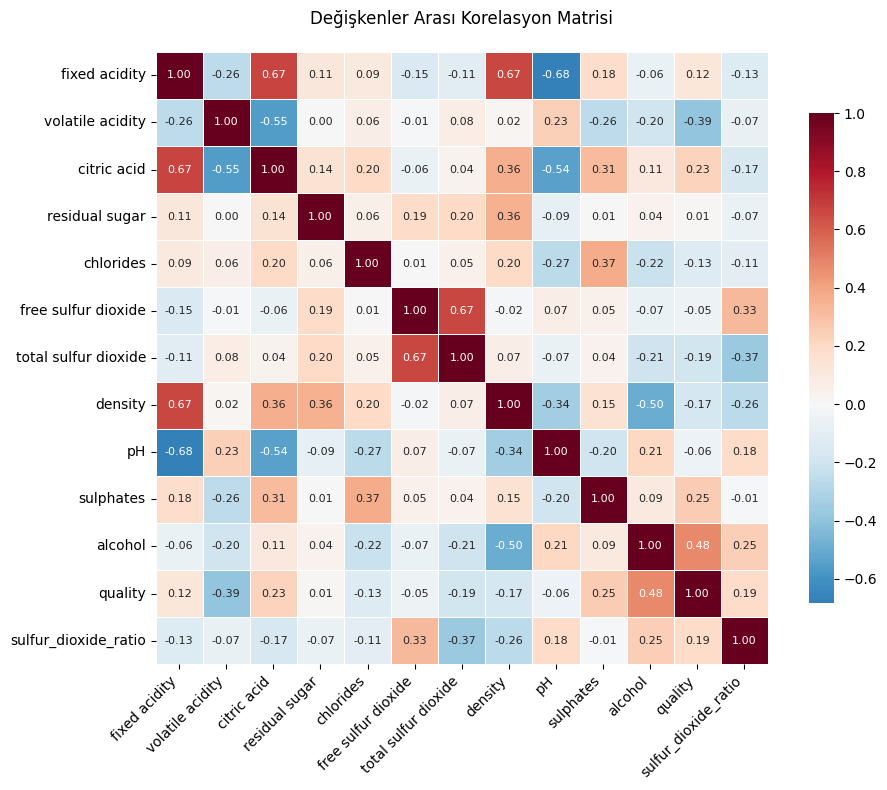

In [26]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

correlation_matrix(df, numeric_cols, (10,8))

## Outliers

In [27]:
cat_cols, num_cols, cat_but_car = grab_col_names(df)


Observations: 1599
Variables: 15
cat_cols: 3
num_cols: 12
cat_but_car: 0
num_but_cat: 3


In [28]:
for col in num_cols:
    print(col, check_outlier(df, col))


fixed acidity True
volatile acidity True
citric acid True
residual sugar True
chlorides True
free sulfur dioxide True
total sulfur dioxide True
density True
pH True
sulphates True
alcohol True
sulfur_dioxide_ratio True


In [29]:
def plot_outliers(dataframe, numeric_cols, n_cols=2):
    """
    Sayısal değişkenler için outlier analizi yapan fonksiyon
    
    Parameters:
    -----------
    dataframe: pandas DataFrame
        İncelenecek veri seti
    numeric_cols: list
        İncelenecek sayısal değişken listesi
    n_cols: int, default=2
        Her satırda gösterilecek grafik sayısı
    """
    
    n_rows = int(np.ceil(len(numeric_cols)/n_cols))
    plt.figure(figsize=(n_cols*6, n_rows*4))
    
    for idx, col in enumerate(numeric_cols, 1):
        plt.subplot(n_rows, n_cols, idx)
        
        # Box plot
        sns.boxplot(y=dataframe[col], color='lightblue')
        plt.title(f'{col} - Box Plot')
        
    plt.tight_layout()
    plt.show()
    
    # Detaylı istatistikler ve outlier sayıları
    for col in numeric_cols:
        Q1 = dataframe[col].quantile(0.25)
        Q3 = dataframe[col].quantile(0.75)
        IQR = Q3 - Q1
        low_limit = Q1 - 1.5 * IQR
        up_limit = Q3 + 1.5 * IQR
        
        outliers = dataframe[(dataframe[col] < low_limit) | (dataframe[col] > up_limit)][col]
        
        print(f"\n{col} için outlier istatistikleri:")
        print(f"Alt limit: {low_limit:.2f}")
        print(f"Üst limit: {up_limit:.2f}")
        print(f"Outlier sayısı: {len(outliers)}")
        print(f"Outlier oranı: {(len(outliers)/len(dataframe))*100:.2f}%")
        if len(outliers) > 0:
            print(f"Outlier değerler: \n{outliers.describe()}")
            
def plot_outliers_scatter(dataframe, numeric_cols, n_cols=2):
    """
    Sayısal değişkenler için scatter plot ile outlier analizi
    """
    n_rows = int(np.ceil(len(numeric_cols)/n_cols))
    plt.figure(figsize=(n_cols*6, n_rows*4))
    
    for idx, col in enumerate(numeric_cols, 1):
        plt.subplot(n_rows, n_cols, idx)
        
        # Scatter plot
        plt.scatter(range(len(dataframe)), dataframe[col], alpha=0.5)
        plt.title(f'{col} - Scatter Plot')
        plt.xlabel('Index')
        plt.ylabel(col)
        
    plt.tight_layout()
    plt.show()

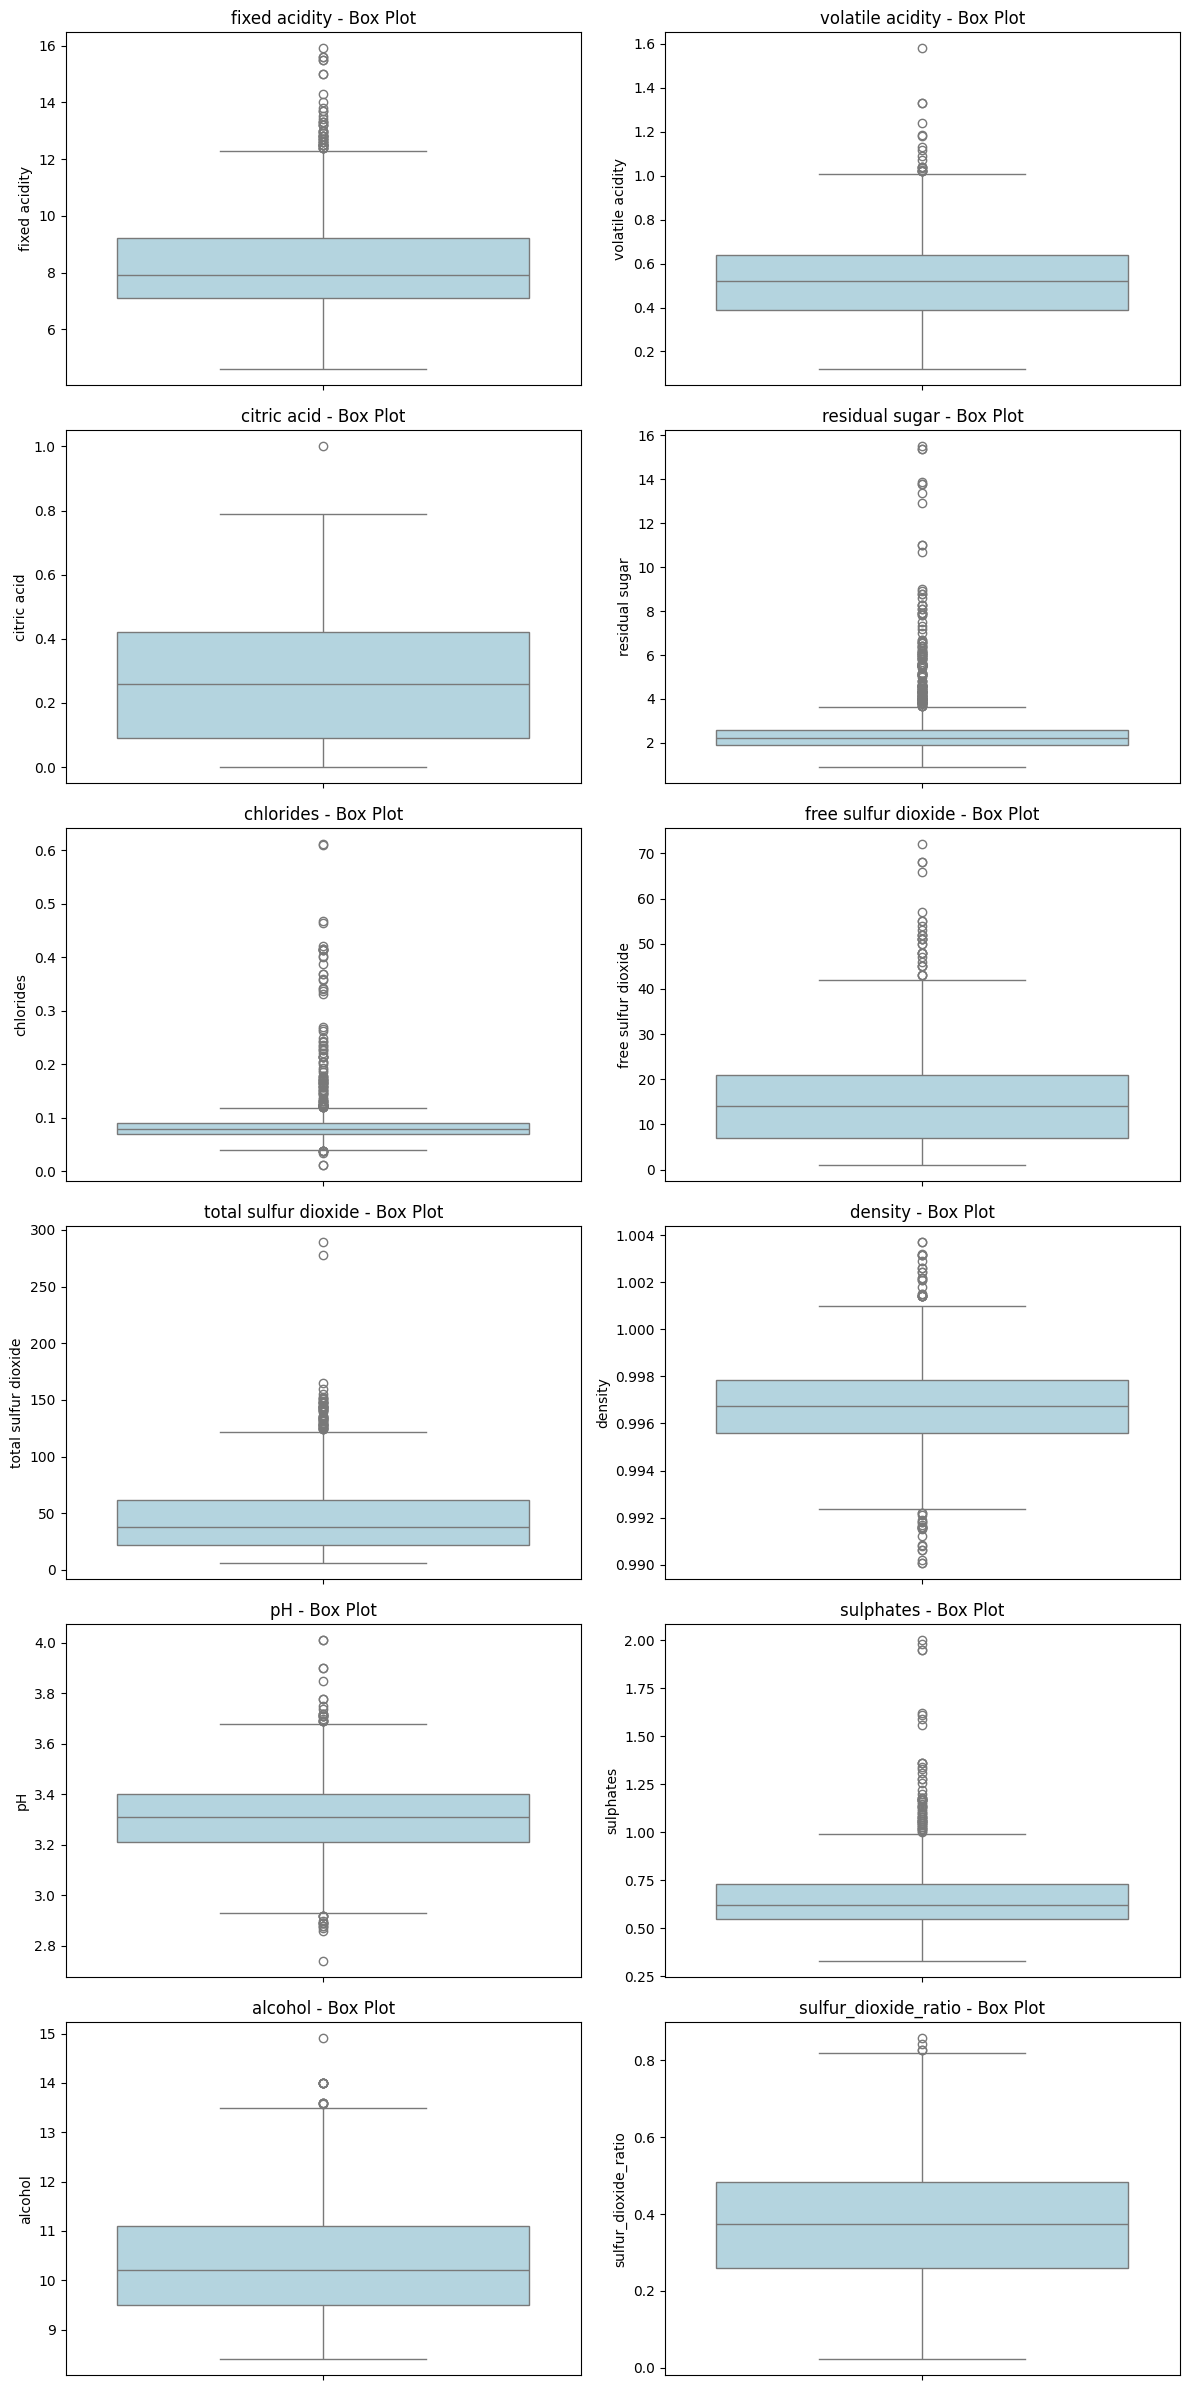


fixed acidity için outlier istatistikleri:
Alt limit: 3.95
Üst limit: 12.35
Outlier sayısı: 49
Outlier oranı: 3.06%
Outlier değerler: 
count   49.000
mean    13.288
std      0.999
min     12.400
25%     12.600
50%     12.900
75%     13.500
max     15.900
Name: fixed acidity, dtype: float64

volatile acidity için outlier istatistikleri:
Alt limit: 0.02
Üst limit: 1.02
Outlier sayısı: 19
Outlier oranı: 1.19%
Outlier değerler: 
count   19.000
mean     1.132
std      0.149
min      1.020
25%      1.030
50%      1.070
75%      1.183
max      1.580
Name: volatile acidity, dtype: float64

citric acid için outlier istatistikleri:
Alt limit: -0.40
Üst limit: 0.91
Outlier sayısı: 1
Outlier oranı: 0.06%
Outlier değerler: 
count   1.000
mean    1.000
std       NaN
min     1.000
25%     1.000
50%     1.000
75%     1.000
max     1.000
Name: citric acid, dtype: float64

residual sugar için outlier istatistikleri:
Alt limit: 0.85
Üst limit: 3.65
Outlier sayısı: 155
Outlier oranı: 9.69%
Outlier değerl

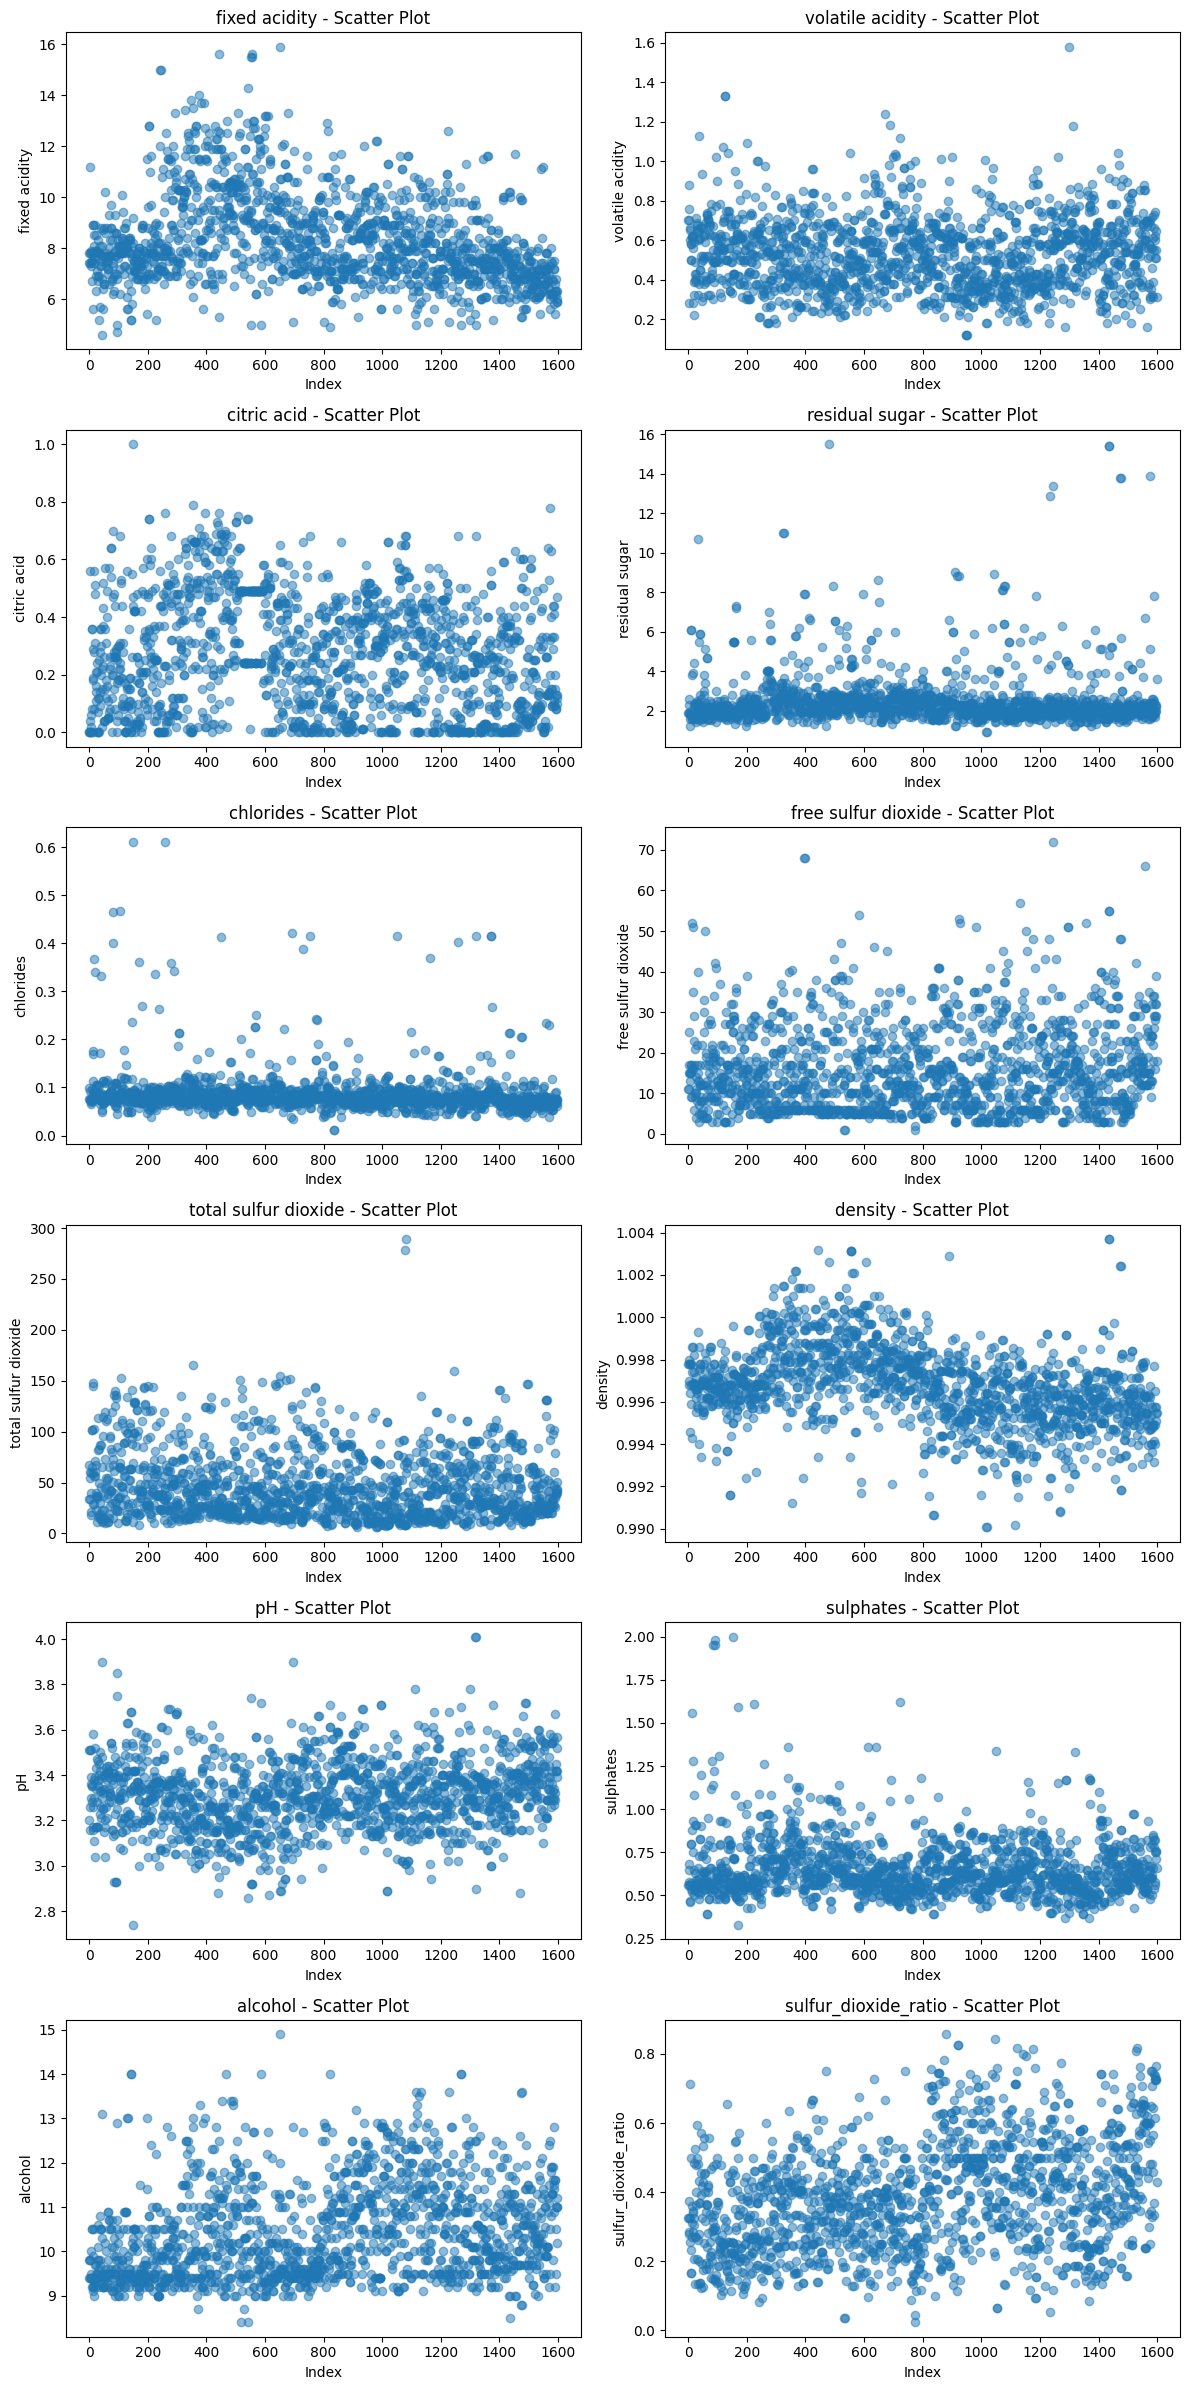

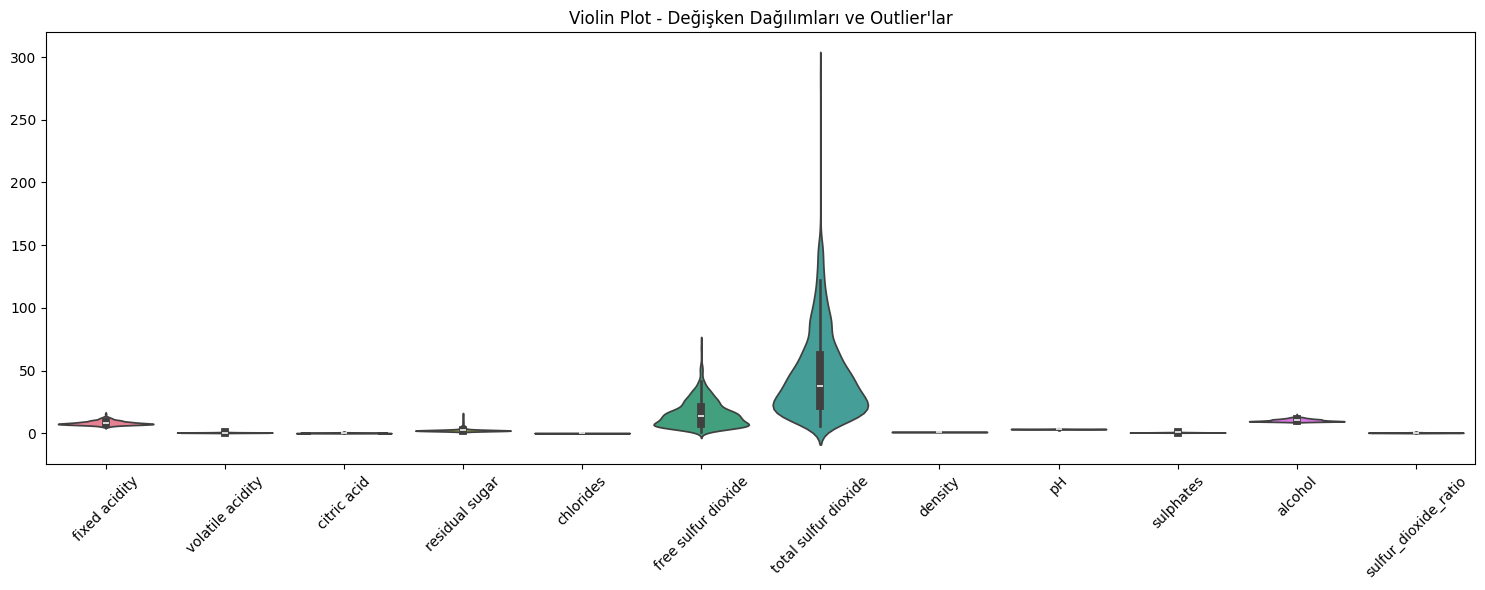

In [30]:
# Kullanım örneği:
# Sayısal değişkenleri seç
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
numeric_cols = numeric_cols.drop('quality') if 'quality' in numeric_cols else numeric_cols

# Box plot ve istatistikler
plot_outliers(df, numeric_cols)

# Scatter plot
plot_outliers_scatter(df, numeric_cols)

# Violin plot ile dağılım ve outlier'ları görselleştirme
plt.figure(figsize=(15, 6))
sns.violinplot(data=df[numeric_cols])
plt.xticks(rotation=45)
plt.title('Violin Plot - Değişken Dağılımları ve Outlier\'lar')
plt.tight_layout()
plt.show()

In [31]:
for col in num_cols:
    print(col, check_outlier(df, col))

fixed acidity True
volatile acidity True
citric acid True
residual sugar True
chlorides True
free sulfur dioxide True
total sulfur dioxide True
density True
pH True
sulphates True
alcohol True
sulfur_dioxide_ratio True


In [32]:
for col in num_cols:
    replace_with_thresholds(df, col)


In [33]:
for col in num_cols:
    print(col, check_outlier(df, col))



fixed acidity False
volatile acidity False
citric acid False
residual sugar False
chlorides False
free sulfur dioxide False
total sulfur dioxide False
density False
pH False
sulphates False
alcohol False
sulfur_dioxide_ratio False


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   fixed acidity         1599 non-null   float64 
 1   volatile acidity      1599 non-null   float64 
 2   citric acid           1599 non-null   float64 
 3   residual sugar        1599 non-null   float64 
 4   chlorides             1599 non-null   float64 
 5   free sulfur dioxide   1599 non-null   float64 
 6   total sulfur dioxide  1599 non-null   float64 
 7   density               1599 non-null   float64 
 8   pH                    1599 non-null   float64 
 9   sulphates             1599 non-null   float64 
 10  alcohol               1599 non-null   float64 
 11  quality               1599 non-null   int64   
 12  sulfur_dioxide_ratio  1599 non-null   float64 
 13  alcohol_level         1599 non-null   category
 14  acidity_level         1599 non-null   category
dtypes: c

## Missing Values

In [35]:
def missing_values_table(dataframe, na_name=False):
    na_columns = [col for col in dataframe.columns if dataframe[col].isnull().sum() > 0]

    n_miss = dataframe[na_columns].isnull().sum().sort_values(ascending=False)
    ratio = (dataframe[na_columns].isnull().sum() / dataframe.shape[0] * 100).sort_values(ascending=False)
    missing_df = pd.concat([n_miss, np.round(ratio, 2)], axis=1, keys=['n_miss', 'ratio'])
    print(missing_df, end="\n")

    if na_name:
        return na_columns

In [36]:
missing_values_table(df)


Empty DataFrame
Columns: [n_miss, ratio]
Index: []


In [37]:
df.columns.isna()

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False])

## Label Encoding

In [38]:
binary_cols = [col for col in df.columns if df[col].dtype not in [int, float] and df[col].nunique() == 2]

In [39]:
binary_cols

[]

## One-Hot Encoding

In [40]:
ohe_cols = [col for col in df.columns if 10 > df[col].nunique() > 2]

In [41]:
ohe_cols

['quality', 'alcohol_level', 'acidity_level']

In [42]:
ohe_cols.remove('quality')

In [43]:
def one_hot_encoder(dataframe, categorical_cols, drop_first=True):
    dataframe = pd.get_dummies(dataframe, columns=categorical_cols, drop_first=drop_first)
    return dataframe

In [44]:
df = one_hot_encoder(df, ohe_cols)

In [45]:
df.dtypes

fixed acidity              float64
volatile acidity           float64
citric acid                float64
residual sugar             float64
chlorides                  float64
free sulfur dioxide        float64
total sulfur dioxide       float64
density                    float64
pH                         float64
sulphates                  float64
alcohol                    float64
quality                      int64
sulfur_dioxide_ratio       float64
alcohol_level_medium          bool
alcohol_level_high            bool
alcohol_level_very_high       bool
acidity_level_medium          bool
acidity_level_high            bool
dtype: object

In [46]:
cat_cols, num_cols, cat_but_car = grab_col_names(df)

Observations: 1599
Variables: 18
cat_cols: 6
num_cols: 12
cat_but_car: 0
num_but_cat: 6


In [47]:
cat_cols

['quality',
 'alcohol_level_medium',
 'alcohol_level_high',
 'alcohol_level_very_high',
 'acidity_level_medium',
 'acidity_level_high']

In [48]:
num_cols

['fixed acidity',
 'volatile acidity',
 'citric acid',
 'residual sugar',
 'chlorides',
 'free sulfur dioxide',
 'total sulfur dioxide',
 'density',
 'pH',
 'sulphates',
 'alcohol',
 'sulfur_dioxide_ratio']

In [49]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,sulfur_dioxide_ratio,alcohol_level_medium,alcohol_level_high,alcohol_level_very_high,acidity_level_medium,acidity_level_high
0,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5,0.324,False,False,False,False,True
1,7.800,0.880,0.000,2.600,0.098,25.000,67.000,0.997,3.200,0.680,9.800,5,0.373,True,False,False,False,True
2,7.800,0.760,0.040,2.300,0.092,15.000,54.000,0.997,3.260,0.650,9.800,5,0.278,True,False,False,False,True
3,11.200,0.280,0.560,1.900,0.075,17.000,60.000,0.998,3.160,0.580,9.800,6,0.283,True,False,False,False,False
4,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5,0.324,False,False,False,False,True


## PCA

In [50]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop('quality', axis=1))

In [51]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

In [52]:
explained_variance = pca.explained_variance_ratio_

In [53]:
cumulative_variance_ratio = np.cumsum(explained_variance)

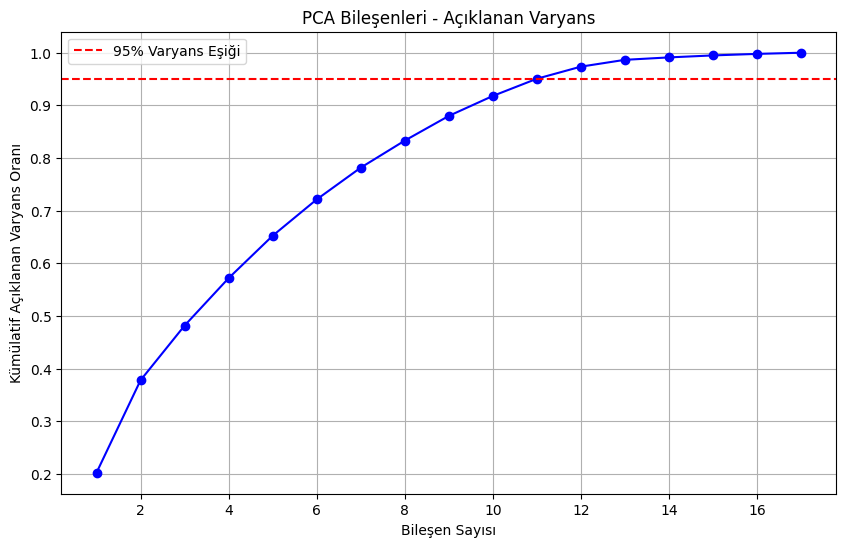

In [54]:
# Bileşenlerin açıkladığı varyans oranlarını görselleştirme
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_variance) + 1), cumulative_variance_ratio, 'bo-')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Varyans Eşiği')
plt.xlabel('Bileşen Sayısı')
plt.ylabel('Kümülatif Açıklanan Varyans Oranı')
plt.title('PCA Bileşenleri - Açıklanan Varyans')
plt.legend()
plt.grid(True)
plt.show()

In [55]:
for i, ratio in enumerate(explained_variance, 1):
    print(f"PC{i}: {ratio:.3f} ({ratio*100:.1f}%)")

PC1: 0.202 (20.2%)
PC2: 0.176 (17.6%)
PC3: 0.104 (10.4%)
PC4: 0.090 (9.0%)
PC5: 0.081 (8.1%)
PC6: 0.069 (6.9%)
PC7: 0.060 (6.0%)
PC8: 0.051 (5.1%)
PC9: 0.047 (4.7%)
PC10: 0.038 (3.8%)
PC11: 0.033 (3.3%)
PC12: 0.023 (2.3%)
PC13: 0.013 (1.3%)
PC14: 0.005 (0.5%)
PC15: 0.004 (0.4%)
PC16: 0.003 (0.3%)
PC17: 0.002 (0.2%)


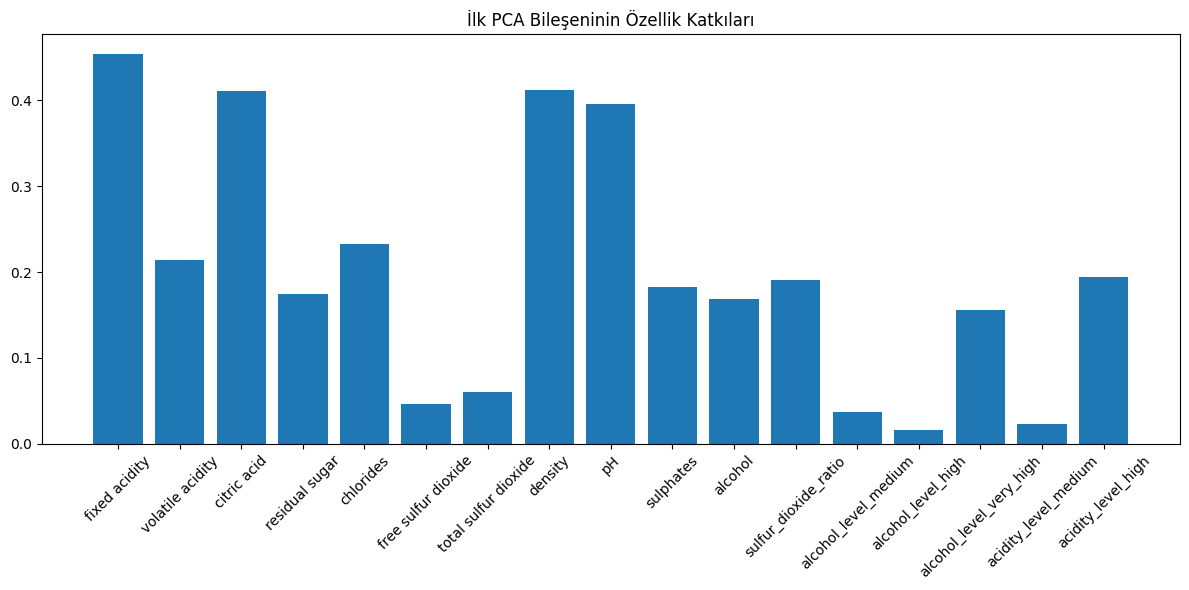

In [56]:
# PCA bileşenlerinin özellik katkılarını görselleştirme
plt.figure(figsize=(12, 6))
features = df.drop('quality', axis=1).columns
plt.bar(features, abs(pca.components_[0]))
plt.xticks(rotation=45)
plt.title('İlk PCA Bileşeninin Özellik Katkıları')
plt.tight_layout()
plt.show()

In [57]:
components_df = pd.DataFrame(
    pca.components_,
    columns=df.drop('quality', axis=1).columns,
    index=[f'PC{i}' for i in range(1, len(pca.components_) + 1)]
)
print("\nPCA Bileşenlerinin Feature Katkıları:")
print(components_df)


PCA Bileşenlerinin Feature Katkıları:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  alcohol  sulfur_dioxide_ratio  alcohol_level_medium  alcohol_level_high  alcohol_level_very_high  acidity_level_medium  acidity_level_high
PC1          -0.454             0.214       -0.411          -0.174     -0.232                0.046                -0.060   -0.412  0.396     -0.182    0.169                 0.191                -0.037              -0.017                    0.156                -0.023               0.194
PC2           0.076            -0.393        0.249          -0.027     -0.205               -0.072                -0.209   -0.222 -0.025      0.192    0.442                 0.187                -0.263               0.079                    0.408                 0.031              -0.355
PC3          -0.178            -0.178        0.008           0.037     -0.061                0.63

In [58]:
target_variance = 0.95  # örneğin %95
n_components = np.argmax(cumulative_variance_ratio >= target_variance) + 1
print(f"\n{target_variance*100}% varyansı açıklamak için gereken minimum bileşen sayısı: {n_components}")


95.0% varyansı açıklamak için gereken minimum bileşen sayısı: 11


In [59]:
final_pca = PCA(n_components=n_components)
X_pca_final = final_pca.fit_transform(X_scaled)

In [60]:
pca_df = pd.DataFrame(
    X_pca_final,
    columns=[f'PC{i}' for i in range(1, n_components + 1)]
)

In [61]:
cat_cols, num_cols, cat_but_car = grab_col_names(pca_df)

Observations: 1599
Variables: 11
cat_cols: 0
num_cols: 11
cat_but_car: 0
num_but_cat: 0


In [62]:
pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11
0,1.636,-2.037,-1.165,0.002,0.240,-0.048,-0.562,0.124,-0.055,-0.478,1.451
1,0.552,-3.073,0.026,1.207,-0.538,0.986,0.707,0.397,0.237,0.925,-0.854
2,0.497,-2.698,-0.768,0.441,-0.787,0.663,0.017,0.554,-0.195,0.581,-0.711
3,-2.602,-0.069,0.177,-0.975,-1.221,1.538,-0.774,-1.011,-0.968,-0.085,-0.617
4,1.636,-2.037,-1.165,0.002,0.240,-0.048,-0.562,0.124,-0.055,-0.478,1.451


In [63]:
scaler = StandardScaler()

In [64]:
pca_df[num_cols] = scaler.fit_transform(pca_df[num_cols])

In [65]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

In [66]:
X = df.drop('quality', axis=1)
y = df['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [67]:
from sklearn.ensemble import RandomForestClassifier

Fitting 5 folds for each of 1458 candidates, totalling 7290 fits

En iyi Random Forest parametreleri: {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Random Forest Test Skoru: 0.63125
OOB Skor: 0.6575449569976545

Özellik Önem Sıralaması:
   feature  importance
9     PC10       0.120
1      PC2       0.118
10    PC11       0.117
4      PC5       0.085
11    PC12       0.076
7      PC8       0.068
6      PC7       0.067
2      PC3       0.067
8      PC9       0.057
0      PC1       0.057
3      PC4       0.055
5      PC6       0.052
14    PC15       0.023
16    PC17       0.015
12    PC13       0.007
15    PC16       0.007
13    PC14       0.007

Model Analizi:
Son eğitim skoru: 0.902
Son validasyon skoru: 0.569
Eğitim-Validasyon farkı: 0.334
Uyarı: Model overfitting eğilimi gösteriyor.


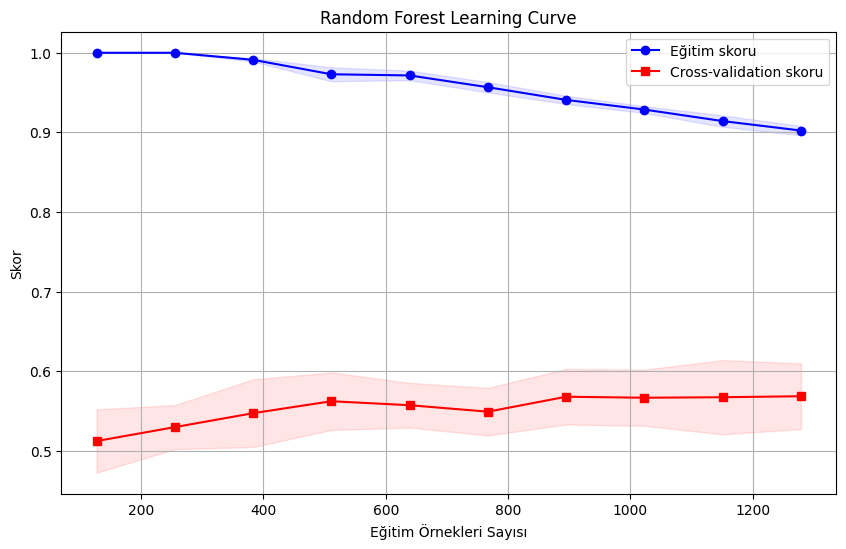

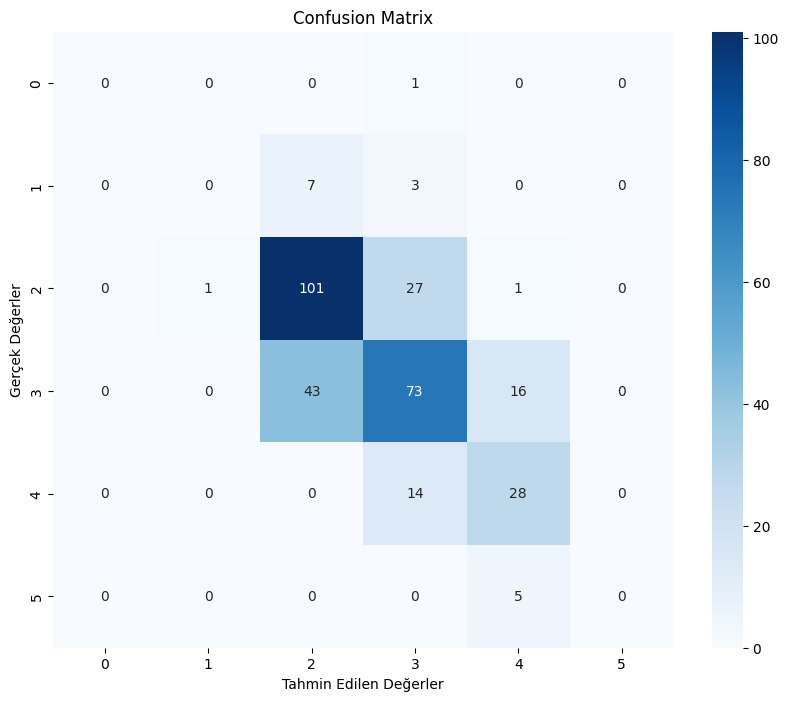


Sınıflandırma Raporu:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.67      0.78      0.72       130
           6       0.62      0.55      0.58       132
           7       0.56      0.67      0.61        42
           8       0.00      0.00      0.00         5

    accuracy                           0.63       320
   macro avg       0.31      0.33      0.32       320
weighted avg       0.60      0.63      0.61       320



c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modif

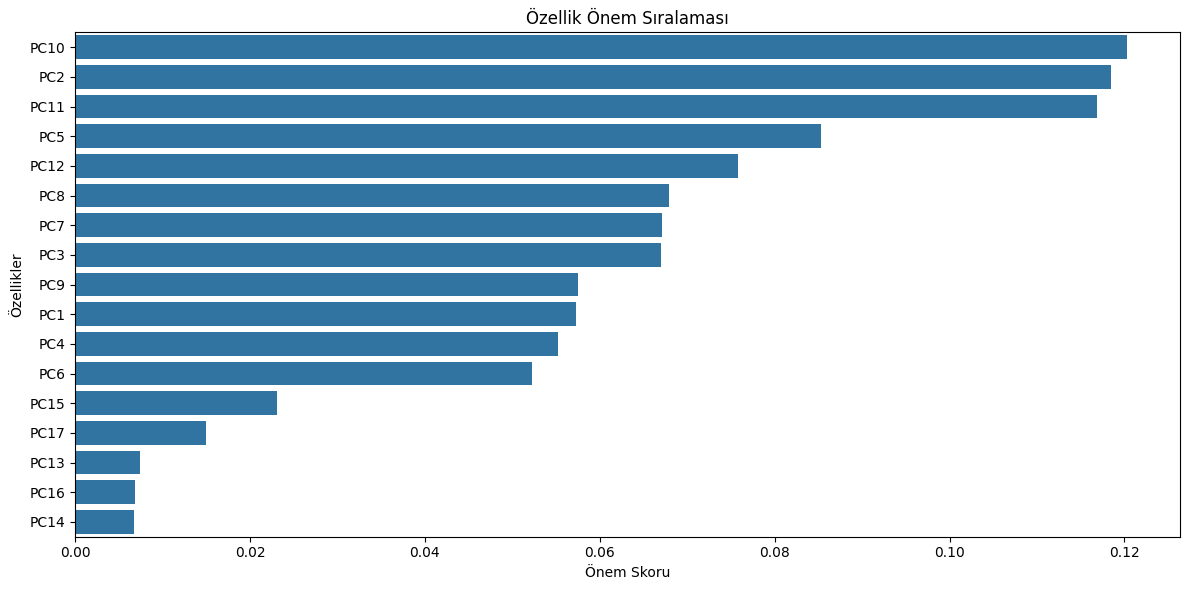


Cross Validation Skorları:
Ortalama CV Skoru: 0.565 (+/- 0.073)

Final Model Performans Özeti:
En İyi Parametreler: {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Test Seti Doğruluk Oranı: 0.631
OOB Skor: 0.658
Cross Validation Ortalama Skoru: 0.565


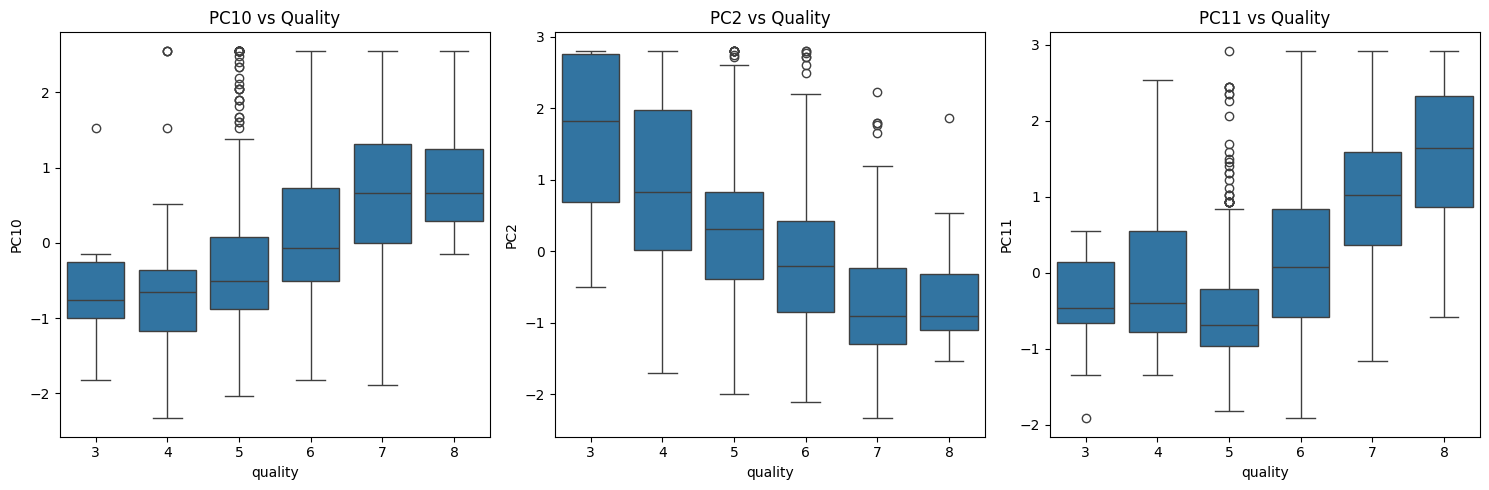

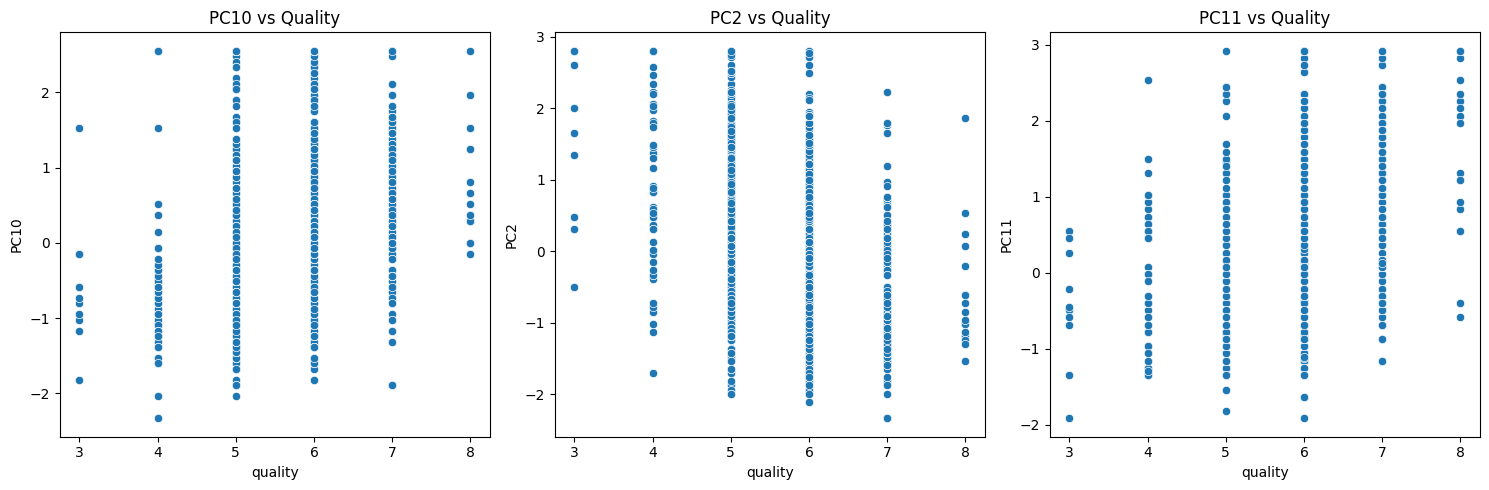

In [68]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_score, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


pca_columns = [f'PC{i+1}' for i in range(X_scaled.shape[1])]
X_df = pd.DataFrame(X_scaled, columns=pca_columns)


X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)


rf_params = {
    'n_estimators': [100, 200, 300],  # Daha fazla ağaç
    'max_depth': [5, 8, 10],  # Daha derin ağaçlar
    'min_samples_split': [2, 5, 8],  # Daha düşük minimum örnek sayısı
    'min_samples_leaf': [1, 2, 4],  # Daha düşük leaf örnek sayısı
    'max_features': ['sqrt', 'log2', None],  # Feature seçimi için daha fazla opsiyon
    'class_weight': ['balanced'],
    'max_leaf_nodes': [50, 100, None],  # Daha fazla leaf node
    'min_impurity_decrease': [0.0, 0.01]  # Daha düşük impurity threshold
}


rf = RandomForestClassifier(
    random_state=42,
    bootstrap=True,
    oob_score=True,
    ccp_alpha=0.001,  # Daha düşük complexity pruning
    criterion='gini'  # Gini kullan
)


rf_grid = GridSearchCV(
    rf, 
    rf_params, 
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)


rf_grid.fit(X_train, y_train)


print("\nEn iyi Random Forest parametreleri:", rf_grid.best_params_)
print("Random Forest Test Skoru:", rf_grid.score(X_test, y_test))
print("OOB Skor:", rf_grid.best_estimator_.oob_score_)


feature_importance = pd.DataFrame({
    'feature': pca_columns,
    'importance': rf_grid.best_estimator_.feature_importances_
}).sort_values('importance', ascending=False)

print("\nÖzellik Önem Sıralaması:")
print(feature_importance)

def plot_learning_curve(estimator, X, y, title="Learning Curve"):
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, 
        X, 
        y, 
        cv=5,
        n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10),
        scoring='accuracy'
    )
    
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)
    
    plt.figure(figsize=(10, 6))
    plt.plot(train_sizes, train_mean, label='Eğitim skoru', color='blue', marker='o')
    plt.plot(train_sizes, test_mean, label='Cross-validation skoru', color='red', marker='s')
    
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
    plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color='red')
    
    plt.title(title)
    plt.xlabel('Eğitim Örnekleri Sayısı')
    plt.ylabel('Skor')
    plt.legend(loc='best')
    plt.grid(True)
    
    gap = train_mean[-1] - test_mean[-1]
    print(f"\nModel Analizi:")
    print(f"Son eğitim skoru: {train_mean[-1]:.3f}")
    print(f"Son validasyon skoru: {test_mean[-1]:.3f}")
    print(f"Eğitim-Validasyon farkı: {gap:.3f}")
    
    if gap > 0.1:
        print("Uyarı: Model overfitting eğilimi gösteriyor.")
    elif test_mean[-1] < 0.6:
        print("Uyarı: Model underfitting eğilimi gösteriyor.")
    
    plt.show()


plot_learning_curve(rf_grid.best_estimator_, X_scaled, y, "Random Forest Learning Curve")


y_pred = rf_grid.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('Gerçek Değerler')
plt.xlabel('Tahmin Edilen Değerler')
plt.show()


print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(12, 6))
sns.barplot(x='importance', y='feature', data=feature_importance)
plt.title('Özellik Önem Sıralaması')
plt.xlabel('Önem Skoru')
plt.ylabel('Özellikler')
plt.tight_layout()
plt.show()

cv_scores = cross_val_score(rf_grid.best_estimator_, X_scaled, y, cv=5)
print("\nCross Validation Skorları:")
print(f"Ortalama CV Skoru: {cv_scores.mean():.3f} (+/- {cv_scores.std() * 2:.3f})")

print("\nFinal Model Performans Özeti:")
print(f"En İyi Parametreler: {rf_grid.best_params_}")
print(f"Test Seti Doğruluk Oranı: {rf_grid.score(X_test, y_test):.3f}")
print(f"OOB Skor: {rf_grid.best_estimator_.oob_score_:.3f}")
print(f"Cross Validation Ortalama Skoru: {cv_scores.mean():.3f}")


X_df['quality'] = y  # Target değişkeni ekleyelim
top_features = feature_importance.head(3)['feature'].tolist()

plt.figure(figsize=(15, 5))
for i, feature in enumerate(top_features, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(x='quality', y=feature, data=X_df)
    plt.title(f'{feature} vs Quality')
plt.tight_layout()
plt.show()


plt.figure(figsize=(15, 5))
for i, feature in enumerate(top_features, 1):
    plt.subplot(1, 3, i)
    sns.scatterplot(x='quality', y=feature, data=X_df)
    plt.title(f'{feature} vs Quality')
plt.tight_layout()
plt.show()

In [71]:
from lightgbm import LGBMClassifier

In [74]:
lgbm_params = {
    'n_estimators': [100, 200, 300],
    'num_leaves': [31, 62, 93],
    'learning_rate': [0.01, 0.1, 0.3],
    'feature_fraction': [0.8, 0.9, 1.0]
}

lgbm = LGBMClassifier(random_state=42)
lgbm_grid = GridSearchCV(lgbm, lgbm_params, cv=5, scoring='accuracy', n_jobs=-1)
lgbm_grid.fit(X_train, y_train)

print("En iyi LightGBM parametreleri:", lgbm_grid.best_params_)
print("LightGBM Test Skoru:", lgbm_grid.score(X_test, y_test))

[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002896 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1179
[LightGBM] [Info] Number of data points in the train set: 1279, number of used features: 17
[LightGBM] [Info] Start training from score -4.956609
[LightGBM] [Info] Start training from score -3.392634
[LightGBM] [Info] Start training from score -0.842099
[LightGBM] [Info] Start training from score -0.927297
[LightGBM] [Info] Start training from score -2.097588
[LightGBM] [Info] Start training from score -4.588884
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best g

In [75]:
# En iyi modeli seçelim (örneğin XGBoost)
best_model = rf_grid.best_estimator_

# Tahminler
y_pred = best_model.predict(X_test)

# Detaylı metrikler
print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_pred))

print("\nKarmaşıklık Matrisi:")
print(confusion_matrix(y_test, y_pred))

# Cross-validation skorları
cv_scores = cross_val_score(best_model, X, y, cv=5, scoring='accuracy')
print("\nCross-validation skorları:", cv_scores)
print("Ortalama CV skoru: %0.2f (+/- %0.2f)" % (cv_scores.mean(), cv_scores.std() * 2))


Sınıflandırma Raporu:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.67      0.78      0.72       130
           6       0.62      0.55      0.58       132
           7       0.56      0.67      0.61        42
           8       0.00      0.00      0.00         5

    accuracy                           0.63       320
   macro avg       0.31      0.33      0.32       320
weighted avg       0.60      0.63      0.61       320


Karmaşıklık Matrisi:
[[  0   0   0   1   0   0]
 [  0   0   7   3   0   0]
 [  0   1 101  27   1   0]
 [  0   0  43  73  16   0]
 [  0   0   0  14  28   0]
 [  0   0   0   0   5   0]]


c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modif


Cross-validation skorları: [0.525      0.528125   0.6125     0.55       0.60501567]
Ortalama CV skoru: 0.56 (+/- 0.08)


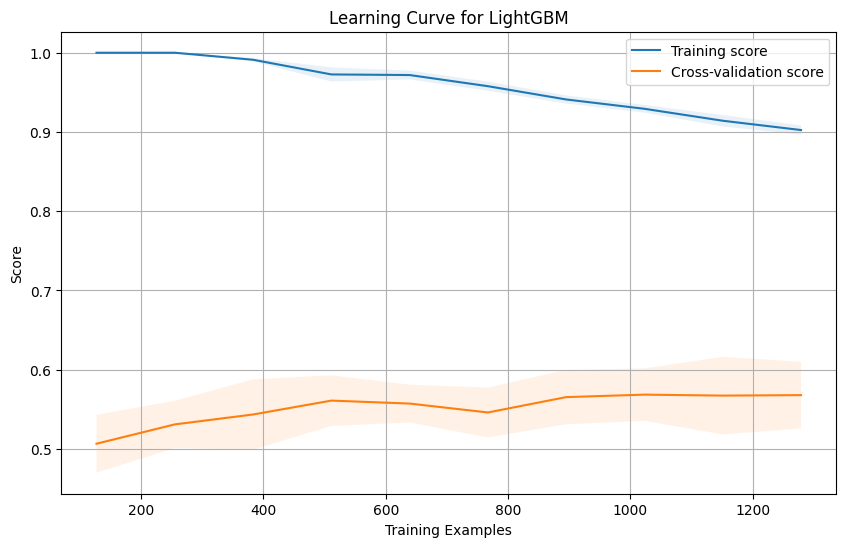

In [76]:
# Learning curve analizi için
from sklearn.model_selection import learning_curve

def plot_learning_curve(estimator, X, y, title="Learning Curve"):
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=5, n_jobs=-1, 
        train_sizes=np.linspace(0.1, 1.0, 10))
    
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)
    
    plt.figure(figsize=(10,6))
    plt.plot(train_sizes, train_mean, label='Training score')
    plt.plot(train_sizes, test_mean, label='Cross-validation score')
    
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
    plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1)
    
    plt.title(title)
    plt.xlabel('Training Examples')
    plt.ylabel('Score')
    plt.legend(loc='best')
    plt.grid(True)
    plt.show()

# Modeller için learning curve çizimi
plot_learning_curve(best_model, X, y, "Learning Curve for LightGBM")

In [78]:
# Gerekli kütüphaneleri içe aktaralım
import autosklearn.classification
import sklearn.model_selection
import sklearn.metrics
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

In [79]:
# Verileri ölçeklendirelim
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Auto-sklearn sınıflandırıcısını güncel parametrelerle oluşturalım
automl = autosklearn.classification.AutoSklearnClassifier(
    time_left_for_this_task=300,  # 5 dakika
    per_run_time_limit=30,        # Her model denemesi için 30 saniye
    ensemble_kwargs={'ensemble_size': 50},
    metric=autosklearn.metrics.accuracy,
    resampling_strategy='cv',
    resampling_strategy_arguments={'folds': 5},
    memory_limit=20480  # 3GB bellek limiti (megabyte cinsinden)
)

In [80]:
# Modeli eğitelim
automl.fit(X_train_scaled, y_train)

AutoSklearnClassifier(ensemble_class=<class 'autosklearn.ensembles.ensemble_selection.EnsembleSelection'>,
                      ensemble_kwargs={'ensemble_size': 50}, memory_limit=20480,
                      metric=accuracy, per_run_time_limit=30,
                      resampling_strategy='cv',
                      resampling_strategy_arguments={'folds': 5},
                      time_left_for_this_task=300)

In [91]:
# Sonuçları değerlendirelim
y_pred = automl.predict(X_test_scaled)
print("\nModel Performansı:")
print("Accuracy:", sklearn.metrics.accuracy_score(y_test, y_pred))
print("\nSınıflandırma Raporu:")
print(sklearn.metrics.classification_report(y_test, y_pred))


Model Performansı:
Accuracy: 0.665625

Sınıflandırma Raporu:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.71      0.78      0.74       130
           6       0.62      0.70      0.66       132
           7       0.67      0.43      0.52        42
           8       0.00      0.00      0.00         5

    accuracy                           0.67       320
   macro avg       0.33      0.32      0.32       320
weighted avg       0.63      0.67      0.64       320



/root/miniconda3/envs/autosklearn/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/root/miniconda3/envs/autosklearn/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/root/miniconda3/envs/autosklearn/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result)

In [92]:
# Model istatistiklerini görelim
print("\nOtomatik Makine Öğrenmesi İstatistikleri:")
print(automl.sprint_statistics())


Otomatik Makine Öğrenmesi İstatistikleri:
auto-sklearn results:
  Dataset name: 886632e3-ddfb-11ef-8bfb-fc349702228d
  Metric: accuracy
  Best validation score: 0.698202
  Number of target algorithm runs: 17
  Number of successful target algorithm runs: 9
  Number of crashed target algorithm runs: 0
  Number of target algorithms that exceeded the time limit: 8
  Number of target algorithms that exceeded the memory limit: 0



In [93]:
# En iyi modelleri görelim
print("\nEn İyi Modeller:")
print(automl.leaderboard());


En İyi Modeller:
          rank  ensemble_weight               type  cost  duration
model_id                                                          
2            1            0.200      random_forest 0.302     8.207
4            2            0.120      random_forest 0.303     6.235
3            3            0.160      random_forest 0.317    12.679
6            4            0.120      random_forest 0.325     9.222
17           5            0.220      random_forest 0.368     6.839
13           6            0.080  gradient_boosting 0.371     5.984
14           7            0.060                lda 0.407     2.340
5            8            0.040  gradient_boosting 0.506     2.559


In [94]:
# Karmaşıklık matrisini çizelim
import matplotlib.pyplot as plt
import seaborn as sns

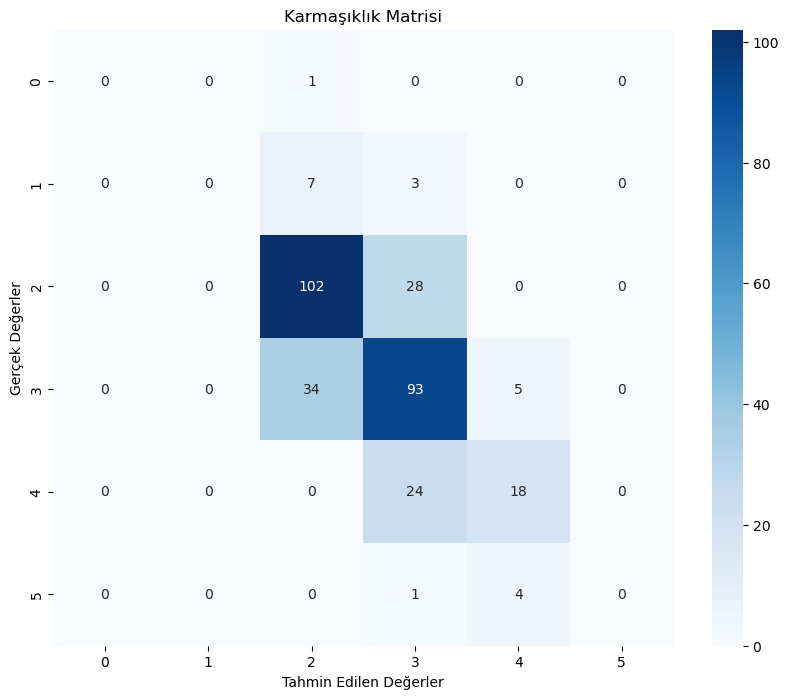

In [95]:
cm = sklearn.metrics.confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Karmaşıklık Matrisi')
plt.ylabel('Gerçek Değerler')
plt.xlabel('Tahmin Edilen Değerler')
plt.show()